Projet IA — Détection Mines vs Rochers (Sonar)
 Ce projet utilise le Machine Learning pour classifier des signaux sonar.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [6]:
df = pd.read_csv('sonar.all-data.csv', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [7]:
print("Nombre de lignes et colonnes :", df.shape)
print("Nombre de Mines (M) et Rochers (R) :")
print(df.iloc[:, -1].value_counts())

Nombre de lignes et colonnes : (208, 61)
Nombre de Mines (M) et Rochers (R) :
60
M    111
R     97
Name: count, dtype: int64


In [9]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [10]:
print("Valeurs manquantes :", df.isnull().sum().sum())

Valeurs manquantes : 0


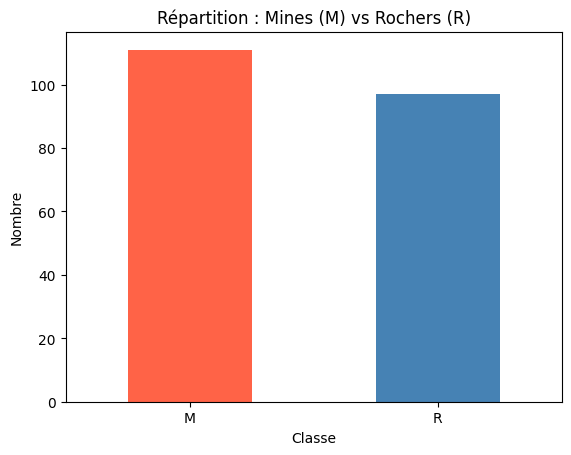

In [11]:
df.iloc[:, -1].value_counts().plot(kind='bar', color=['tomato', 'steelblue'])
plt.title("Répartition : Mines (M) vs Rochers (R)")
plt.xlabel("Classe")
plt.ylabel("Nombre")
plt.xticks(rotation=0)
plt.show()

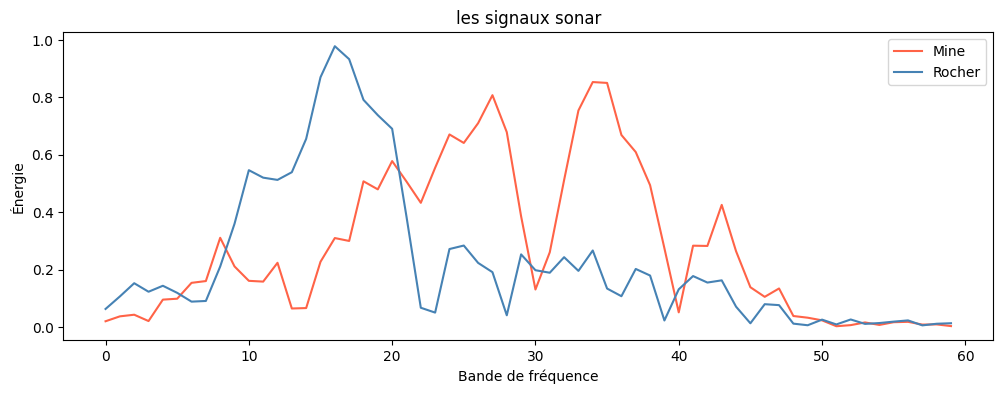

In [13]:
plt.figure(figsize=(12, 4))
plt.plot(df.iloc[0, :-1], color='tomato', label='Mine')
plt.plot(df.iloc[100, :-1], color='steelblue', label='Rocher')
plt.title("les signaux sonar")
plt.xlabel("Bande de fréquence")
plt.ylabel("Énergie")
plt.legend()
plt.show()

In [14]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

print("Taille de X :", X.shape)
print("Taille de y :", y.shape)

Taille de X : (208, 60)
Taille de y : (208,)


In [15]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Avant :", df.iloc[:, -1].values[:5])
print("Après :", y[:5])

Avant : <StringArray>
['R', 'R', 'R', 'R', 'R']
Length: 5, dtype: str
Après : [1 1 1 1 1]


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)

Données d'entraînement : (166, 60)
Données de test : (42, 60)


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalisation terminée ✅")

Normalisation terminée ✅


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [19]:
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)
print("Régression Logistique — Accuracy :", round(acc_lr * 100, 2), "%")

Régression Logistique — Accuracy : 80.95 %


In [20]:
model_svm = SVC(kernel='rbf')
model_svm.fit(X_train, y_train)

pred_svm = model_svm.predict(X_test)
acc_svm = accuracy_score(y_test, pred_svm)
print("SVM — Accuracy :", round(acc_svm * 100, 2), "%")

SVM — Accuracy : 88.1 %


In [21]:
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)
acc_rf = accuracy_score(y_test, pred_rf)
print("Random Forest — Accuracy :", round(acc_rf * 100, 2), "%")

Random Forest — Accuracy : 85.71 %


                  Modèle  Accuracy (%)
0  Régression Logistique         80.95
1                    SVM         88.10
2          Random Forest         85.71


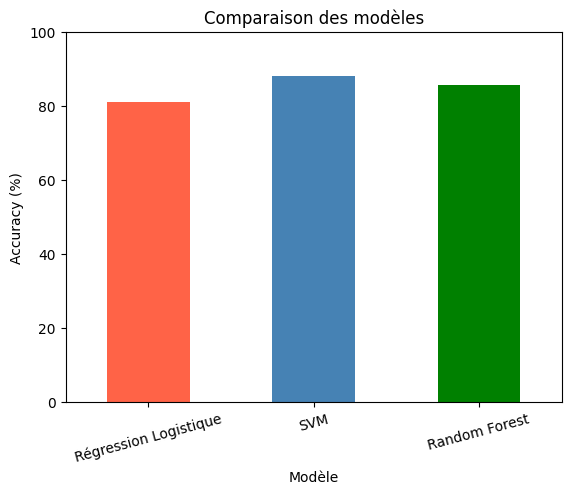

In [22]:
resultats = pd.DataFrame({
    'Modèle': ['Régression Logistique', 'SVM', 'Random Forest'],
    'Accuracy (%)': [round(acc_lr*100, 2), round(acc_svm*100, 2), round(acc_rf*100, 2)]
})

print(resultats)

resultats.plot(kind='bar', x='Modèle', y='Accuracy (%)', 
               color=['tomato', 'steelblue', 'green'], legend=False)
plt.title("Comparaison des modèles")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.show()

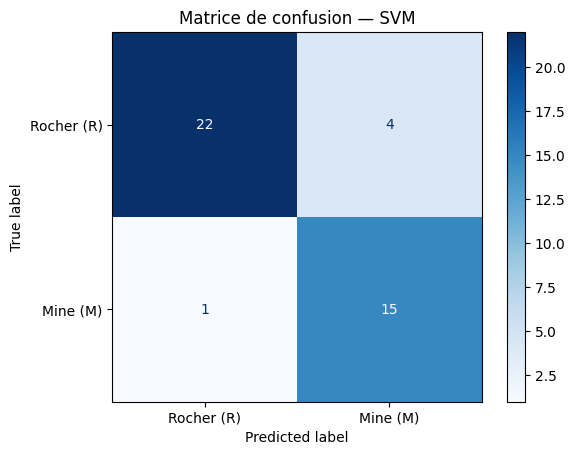

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, pred_svm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['Rocher (R)', 'Mine (M)'])
disp.plot(cmap='Blues')
plt.title("Matrice de confusion — SVM")
plt.show()

In [24]:
from sklearn.metrics import classification_report

print("=== Rapport détaillé — SVM ===")
print(classification_report(y_test, pred_svm, 
                             target_names=['Rocher (R)', 'Mine (M)']))

=== Rapport détaillé — SVM ===
              precision    recall  f1-score   support

  Rocher (R)       0.96      0.85      0.90        26
    Mine (M)       0.79      0.94      0.86        16

    accuracy                           0.88        42
   macro avg       0.87      0.89      0.88        42
weighted avg       0.89      0.88      0.88        42



In [25]:
exemple = X_test[0].reshape(1, -1)
prediction = model_svm.predict(exemple)

if prediction[0] == 1:
    print("🔴 Le modèle prédit : MINE (M) — Danger !")
else:
    print("🟢 Le modèle prédit : ROCHER (R) — Sans danger")

print("Réponse correcte :", "MINE" if y_test[0] == 1 else "ROCHER")

🟢 Le modèle prédit : ROCHER (R) — Sans danger
Réponse correcte : ROCHER


## Conclusion

Dans ce projet, nous avons entraîné 3 modèles de Machine Learning 
pour détecter les mines sous-marines à partir de signaux sonar :

- Régression Logistique : 80.95%
- SVM: 88.10%  
- Random Forest : 85.71%

Le meilleur modèle est le **SVM** avec une accuracy de **88.10%**.

Ce modèle peut aider à détecter automatiquement les mines 
sous-marines et éviter des accidents.

In [26]:
import os
os.makedirs('images', exist_ok=True)
print("Dossier images créé ✅")

Dossier images créé ✅


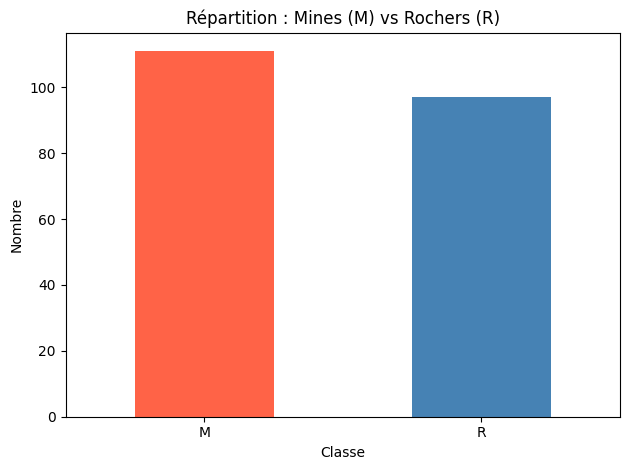

✅ Sauvegardé : images/repartition.png


In [27]:
fig, ax = plt.subplots()
df.iloc[:, -1].value_counts().plot(kind='bar', 
                                    color=['tomato', 'steelblue'], ax=ax)
ax.set_title("Répartition : Mines (M) vs Rochers (R)")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('images/repartition.png', dpi=150)
plt.show()
print("✅ Sauvegardé : images/repartition.png")

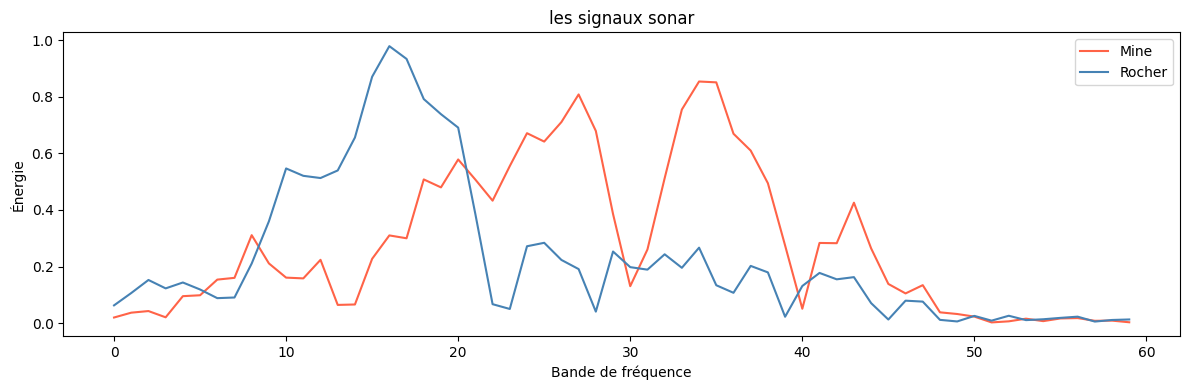

✅ Sauvegardé : images/signaux_sonar.png


In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.iloc[0, :-1], color='tomato', label='Mine')
ax.plot(df.iloc[100, :-1], color='steelblue', label='Rocher')
ax.set_title("les signaux sonar")
ax.set_xlabel("Bande de fréquence")
ax.set_ylabel("Énergie")
ax.legend()
plt.tight_layout()
plt.savefig('images/signaux_sonar.png', dpi=150)
plt.show()
print("✅ Sauvegardé : images/signaux_sonar.png")

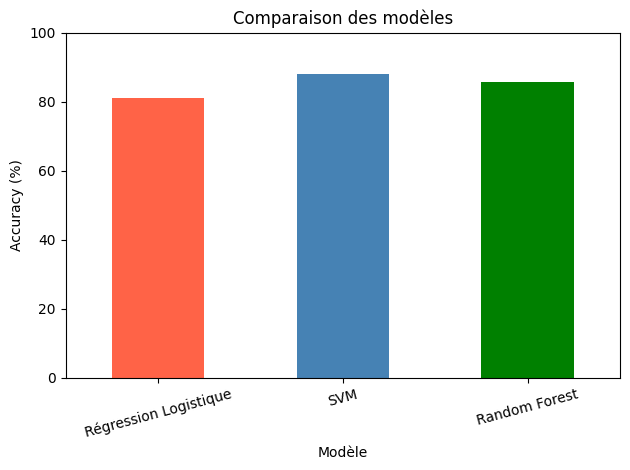

✅ Sauvegardé : images/comparaison_modeles.png


In [30]:
fig, ax = plt.subplots()
resultats.plot(kind='bar', x='Modèle', y='Accuracy (%)',
               color=['tomato', 'steelblue', 'green'], 
               legend=False, ax=ax)
ax.set_title("Comparaison des modèles")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('images/comparaison_modeles.png', dpi=150)
plt.show()
print("✅ Sauvegardé : images/comparaison_modeles.png")

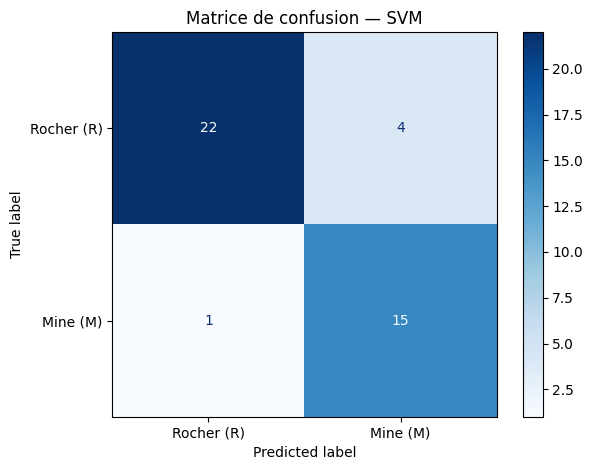

✅ Sauvegardé : images/matrice_confusion.png


In [31]:
fig, ax = plt.subplots()
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Rocher (R)', 'Mine (M)'])
disp.plot(cmap='Blues', ax=ax)
ax.set_title("Matrice de confusion — SVM")
plt.tight_layout()
plt.savefig('images/matrice_confusion.png', dpi=150)
plt.show()
print("✅ Sauvegardé : images/matrice_confusion.png")